# Chapter 4: Joint Distributions and Transformations

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch04/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_04.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Box–Muller and Gamma–Beta Independence

*Source file:* `code/ch04/c04_1_box_muller_gamma_beta.py`

In [2]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
N = 500_000
U1, U2 = rng.random(N), rng.random(N)
Z1 = np.sqrt(-2*np.log(U1)) * np.cos(2*np.pi*U2)
Z2 = np.sqrt(-2*np.log(U1)) * np.sin(2*np.pi*U2)
print(f"Box-Muller: mean=({Z1.mean():+.4f}, {Z2.mean():+.4f}) | var=({Z1.var():.4f}, {Z2.var():.4f})"
      f" | Corr={np.corrcoef(Z1, Z2)[0,1]:+.4f} | Corr(Z1^2,Z2^2)={np.corrcoef(Z1**2, Z2**2)[0,1]:+.4f}")
print(f"KS p-value (Z1 ~ N(0,1)): {stats.kstest(Z1, 'norm').pvalue:.3f}")

a, b = 2.0, 5.0
X, Y = rng.gamma(a, 1, N), rng.gamma(b, 1, N)
U, V = X + Y, X / (X + Y)
print(f"Gamma-Beta: Corr(U, V)={np.corrcoef(U, V)[0,1]:+.4f} | Corr(U, V^2)={np.corrcoef(U, V**2)[0,1]:+.4f}")
print(f"  E[V]={V.mean():.4f} (Beta mean {a/(a+b):.4f}) | E[U]={U.mean():.4f} (Gamma mean {a+b})")
print(f"  KS: V~Beta({a},{b}) p={stats.kstest(V, 'beta', args=(a, b)).pvalue:.3f}")
# A stronger check of independence: is the mean of V constant across slices of U?
q = np.quantile(U, [0, .25, .5, .75, 1])
print("  E[V] within slices of U:", np.round([V[(U >= q[i]) & (U < q[i+1])].mean() for i in range(4)], 4))

Box-Muller: mean=(-0.0006, -0.0021) | var=(1.0024, 1.0002) | Corr=-0.0022 | Corr(Z1^2,Z2^2)=-0.0038
KS p-value (Z1 ~ N(0,1)): 0.835
Gamma-Beta: Corr(U, V)=-0.0002 | Corr(U, V^2)=-0.0003
  E[V]=0.2857 (Beta mean 0.2857) | E[U]=7.0062 (Gamma mean 7.0)


  KS: V~Beta(2.0,5.0) p=0.498
  E[V] within slices of U: [0.2863 0.2853 0.2853 0.286 ]


## Multivariate Normal: Cholesky Generation, Conditional Distribution, Mahalanobis

*Source file:* `code/ch04/c04_2_multivariate_normal_cholesky.py`

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
mu = np.array([170.0, 70.0, 40.0])
sd = np.array([10.0, 12.0, 8.0])
R = np.array([[1.0, 0.6, 0.3], [0.6, 1.0, 0.5], [0.3, 0.5, 1.0]])
Sigma = np.outer(sd, sd) * R
L = np.linalg.cholesky(Sigma)
N = 1_000_000
X = mu + rng.normal(size=(N, 3)) @ L.T
print("Sample covariance - Sigma (largest absolute difference):", np.abs(np.cov(X.T) - Sigma).max().round(3))

# Conditional distribution of X1 | (X2, X3): theoretical and empirical via "slicing"
x2 = np.array([80.0, 45.0])
S12, S22 = Sigma[0, 1:], Sigma[1:, 1:]
m_cond = mu[0] + S12 @ np.linalg.solve(S22, x2 - mu[1:])
v_cond = Sigma[0, 0] - S12 @ np.linalg.solve(S22, S12)
sel = (np.abs(X[:, 1] - x2[0]) < 1.0) & (np.abs(X[:, 2] - x2[1]) < 1.0)
print(f"E[X1|x2,x3]: theory={m_cond:.3f}, slice={X[sel, 0].mean():.3f} | sd: theory={np.sqrt(v_cond):.3f}, slice={X[sel, 0].std():.3f} (n={sel.sum()})")

# Squared Mahalanobis distance ~ chi2_3
D2 = np.einsum("ij,jk,ik->i", X - mu, np.linalg.inv(Sigma), X - mu)
print(f"Mahalanobis D^2: mean={D2.mean():.4f} (3) | P(D^2 > chi2_3,0.05)={np.mean(D2 > stats.chi2.ppf(0.95, 3)):.4f} (0.05)")

Sample covariance - Sigma (largest absolute difference): 0.149
E[X1|x2,x3]: theory=175.000, slice=174.834 | sd: theory=8.000, slice=8.123 (n=5292)
Mahalanobis D^2: mean=2.9988 (3) | P(D^2 > chi2_3,0.05)=0.0499 (0.05)


## Order Statistics and a Vector That Is Not Jointly Normal

*Source file:* `code/ch04/c04_3_order_statistics_not_jointly_normal.py`

U_(1) : mean=0.1003 (k/(n+1)=0.1000) | KS p, Beta(1,9): 0.545
U_(3) : mean=0.2999 (k/(n+1)=0.3000) | KS p, Beta(3,7): 0.391
U_(5) : mean=0.4998 (k/(n+1)=0.5000) | KS p, Beta(5,5): 0.344
U_(9) : mean=0.9000 (k/(n+1)=0.9000) | KS p, Beta(9,1): 0.902
Range: mean=0.7997 (Beta(8,2) mean 0.8000)
Y=SX: Corr(X,Y)=+0.0120 | Corr(X^2,Y^2)=+1.0000 | P(X+Y=0)=0.491


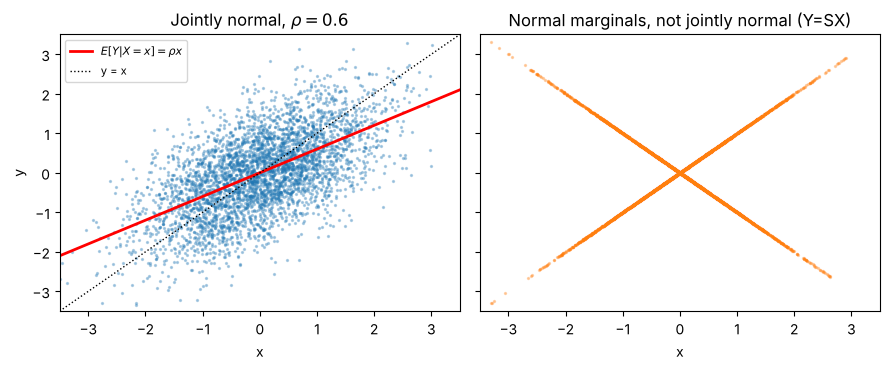

In [4]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n, Rr = 9, 200_000
U = np.sort(rng.random((Rr, n)), axis=1)
for k in [1, 3, 5, 9]:
    print(f"U_({k}) : mean={U[:, k-1].mean():.4f} (k/(n+1)={k/(n+1):.4f}) | KS p, Beta({k},{n-k+1}): "
          f"{stats.kstest(U[:, k-1], 'beta', args=(k, n-k+1)).pvalue:.3f}")
R_ = U[:, -1] - U[:, 0]
print(f"Range: mean={R_.mean():.4f} (Beta({n-1},2) mean {(n-1)/(n+1):.4f})")

X = rng.normal(size=4000)
S = rng.choice([-1, 1], size=X.size)
Y = S * X
print(f"Y=SX: Corr(X,Y)={np.corrcoef(X, Y)[0,1]:+.4f} | Corr(X^2,Y^2)={np.corrcoef(X**2, Y**2)[0,1]:+.4f} | P(X+Y=0)={np.mean(X + Y == 0):.3f}")

rho = 0.6
Z = rng.normal(size=(4000, 2))
B = np.c_[Z[:, 0], rho*Z[:, 0] + np.sqrt(1 - rho**2)*Z[:, 1]]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
ax[0].scatter(B[:, 0], B[:, 1], s=2, alpha=0.3)
xx = np.linspace(-3.5, 3.5, 2)
ax[0].plot(xx, rho*xx, "r-", lw=2, label=r"$E[Y|X=x]=\rho x$")
ax[0].plot(xx, xx, "k:", lw=1, label="y = x")
ax[0].set_title(r"Jointly normal, $\rho=0.6$"); ax[0].legend(fontsize=8)
ax[1].scatter(X, Y, s=2, alpha=0.3, color="tab:orange")
ax[1].set_title("Normal marginals, not jointly normal (Y=SX)")
for a in ax: a.set_xlim(-3.5, 3.5); a.set_ylim(-3.5, 3.5); a.set_xlabel("x")
ax[0].set_ylabel("y"); fig.tight_layout(); fig.savefig("ortak_normal.pdf")